# Capítulo 3 — PD de vida con buckets de riesgo y forward-looking

**De dónde venimos.** El capítulo 2 entregó, para cada cuenta y cada cierre de mes, una PD a 12 meses que **ordena** bien. El capítulo 3 la convierte en lo que pide el ECL: la probabilidad de caer en **cada mes futuro**, hasta el vencimiento, condicionada a los escenarios macro.

$$ECL = \sum_t PD^{marginal}_t \times LGD_t \times EAD_t \times \frac{1}{(1+r)^t}$$

**La idea central.** La PD de hoy dice quién es riesgoso **hoy**. Pero el riesgo de comportamiento **revierte a la media**: el más riesgoso de hoy muchas veces se recupera, y el más sano a veces se deteriora. Por eso no basta con estirar la PD de 12 meses: hay que modelar cómo se **mueven** las cuentas entre niveles de riesgo.

**El método.**
1. La PD del capítulo 2 reparte a las cuentas en **12 buckets de riesgo** cada mes.
2. Una **matriz de transición** mensual dice cómo se mueven entre buckets, cuántas caen en default y cuántas cancelan.
3. Un **factor de ciclo Z**, ligado a la macro, desplaza toda la matriz: en recesión más cuentas empeoran, en expansión más mejoran.
4. Multiplicando las matrices mes a mes salen el **hazard**, la **supervivencia** y la **PD marginal** de cada mes.

**Los datos.** Tres archivos que conversan por `(id, report_date)`:

- `chap2oneypd_mensual.parquet` — la misma base del capítulo 2.
- `estados_mensual.parquet` — el estado de cada cuenta en cada cierre: al día, 1 o 2 cuotas, default, cancelado o castigado.
- `pd_cap2_mensual.parquet` — la PD a 12 meses que exporta la última celda del capítulo 2. **El capítulo 3 no reestima el scorecard: lo recibe.**

**Fecha de reporte: diciembre 2015.** Todo lo que se **estima** usa solo lo observado hasta esa fecha. Todo lo que se **valida** es posterior: ese es el fuera de tiempo.

In [19]:
import pandas as pd, numpy as np, warnings                       # cálculo y tablas
import matplotlib.pyplot as plt                                  # gráficos
plt.style.use('seaborn-v0_8')
import statsmodels.api as sm                                     # regresiones
from scipy.stats import norm                                     # normal: umbrales y factor Z
from scipy.optimize import minimize_scalar                       # estimación del factor Z de cada mes
from statsmodels.tsa.api import VAR                              # modelo macro para los escenarios
warnings.filterwarnings('ignore')

c2 = pd.read_parquet('chap2oneypd_mensual.parquet',
                     columns=['id','report_date','remaining_term','arrears_months',
                              'arrears_event','bankrupt_event','term_expiry_event'])
c2['default_event'] = c2[['arrears_event','bankrupt_event','term_expiry_event']].max(axis=1)
est   = pd.read_parquet('estados_mensual.parquet')               # estado de cada cuenta en cada cierre
pdm   = pd.read_parquet('pd_cap2_mensual.parquet')               # PD a 12 meses del modelo del capítulo 2
macro = pd.read_csv('macro.csv', parse_dates=['report_date'])    # macro TRIMESTRAL, como la entrega economía

T0   = pd.Timestamp('2015-12-31')                                # fecha de reporte: frontera desarrollo / fuera de tiempo
HMAX = 360                                                       # horizonte máximo: 30 años, en meses

print(f'base cap.2 : {len(c2):,} filas | {c2.id.nunique():,} cuentas')
print(f'estados    : {len(est):,} filas | {est.id.nunique():,} cuentas')
print(f'PD cap.2   : {len(pdm):,} filas')

base cap.2 : 2,302,232 filas | 26,100 cuentas
estados    : 2,556,677 filas | 26,341 cuentas
PD cap.2   : 2,302,232 filas


## Las tres bases conversan

Antes de modelar se comprueba que las tres bases describen **la misma cartera en el mismo tiempo**:

1. **Cada fila del capítulo 2 tiene su estado, y coincide** con las cuotas impagas.
2. **El default a 12 meses del capítulo 2 es la entrada a default en los estados.** El evento del corte *t* ocurre en los meses *t+1* a *t+12*, y el estado se ve en el cierre siguiente al evento: la entrada a `DEFAULT` aparece en los cierres *t+2* a *t+13*.

La base de estados tiene **más filas** que la del capítulo 2, y es correcto: incluye los meses en default, las salidas por cancelación o castigo, y los cierres de 2019, que en el capítulo 2 no tienen ventana completa.

In [20]:
m_ = c2.merge(est, on=['id','report_date'], how='left')
mapa = {0: 'AL_DIA', 1: '1_CUOTA', 2: '2_CUOTAS'}
print(f'filas del cap.2 con estado      : {m_.estado.notna().mean()*100:.2f}%')
print(f'estado igual a cuotas impagas   : {(m_.estado.astype(str) == m_.arrears_months.map(mapa)).mean()*100:.3f}%')

cal = sorted(est.report_date.unique()); pos = {d: i for i, d in enumerate(cal)}  # calendario de cierres
es = est.sort_values(['id','report_date']).copy()
es['est'] = es.estado.astype(str)
es['p'] = es.report_date.map(pos)
es['previo'] = es.groupby('id').est.shift(1)
es['siguiente'] = es.groupby('id').est.shift(-1)
es['f_sig'] = es.groupby('id').report_date.shift(-1)
ent = es[(es.est == 'DEFAULT') & (es.previo != 'DEFAULT')].groupby('id').p.apply(list).to_dict()
m_['p'] = m_.report_date.map(pos)
pred = np.array([int(any(2 <= x - p <= 13 for x in ent.get(i, ()))) for i, p in zip(m_.id, m_.p)])
dif = pred != m_.default_event.values
print(f'default 12m = entrada a default : {(~dif).mean()*100:.3f}%  '
      f'(las {dif.sum()} diferencias son del último corte: su default se vería en 2020, fuera del calendario)')
del m_

filas del cap.2 con estado      : 100.00%
estado igual a cuotas impagas   : 100.000%
default 12m = entrada a default : 99.999%  (las 19 diferencias son del último corte: su default se vería en 2020, fuera del calendario)


## De trimestral a mensual

La macro llega **trimestral** y el ECL es **mensual**. La regla depende de cómo viene expresada cada variable:

- **Niveles, o tasas medidas sobre 12 meses** —desempleo, inflación en 12 meses, tasa de referencia—: el dato trimestral es el promedio del trimestre. Se ubica en el **mes central**, se une con una **curva cúbica** (spline de Catmull-Rom, que usa los cuatro trimestres vecinos) y se corrige cada trimestre para que sus tres meses **promedien exactamente** el dato.
- **Flujos** —variación trimestral del PBI y de los precios de vivienda—: se pasan a **tasa mensual equivalente**, se suavizan con la misma cúbica y se corrigen para que tres meses **compuestos** den exactamente la variación del trimestre.

Es exactamente lo que hace el Excel `interpolacion_macro.xlsx`, fórmula por fórmula. Y la misma función se usa para la historia y para los escenarios.

niveles: el promedio de cada trimestre igual al dato -> error máx 1.8e-15
flujos : tres meses compuestos igual al trimestre   -> error máx 4.8e-14


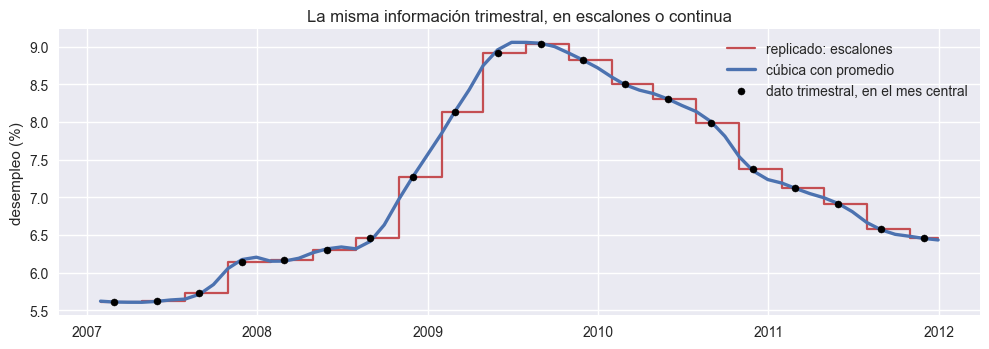

In [21]:
NIVELES, FLUJOS = ['uer', 'ir', 'cpi'], ['gdp_growth', 'hpi']

def cubica_meses(v):
    # Catmull-Rom entre meses centrales: v trimestral (n) -> 3n meses. Mismo cálculo que el Excel.
    n = len(v); j = np.arange(1, 3*n + 1)
    k = (j + 1) // 3                                               # trimestre a la izquierda del mes
    t = (j - (3*k - 1)) / 3                                        # posición entre dos meses centrales: 0, 1/3, 2/3
    P = lambda i: v[np.clip(i, 1, n) - 1]                          # trimestre i, recortado en los bordes
    P0, P1, P2, P3 = P(k-1), P(k), P(k+1), P(k+2)
    return 0.5*(2*P1 + (P2-P0)*t + (2*P0-5*P1+4*P2-P3)*t**2 + (-P0+3*P1-3*P2+P3)*t**3)

def a_mensual(mq):
    # macro trimestral (fechada a fin de trimestre) -> mensual
    meses = pd.date_range(mq.report_date.min() - pd.offsets.MonthEnd(2), mq.report_date.max(), freq='ME')
    trim = np.repeat(np.arange(len(mq)), 3)                        # a qué trimestre pertenece cada mes
    out = pd.DataFrame(index=meses)
    for v in NIVELES:                                              # niveles: cúbica con preservación del promedio
        x = mq[v].values.astype(float); c = cubica_meses(x)
        ajuste = x - pd.Series(c).groupby(trim).mean().values      # dato menos promedio de la cúbica en el trimestre
        out[v] = c + ajuste[trim]
    for v in FLUJOS:                                               # flujos: tasa mensual suavizada y compuesta exacta
        g = mq[v].values.astype(float) / 100
        c = cubica_meses(((1 + g)**(1/3) - 1))                     # tasa mensual equivalente, suavizada
        prod = pd.Series(np.log1p(c)).groupby(trim).sum().values   # log del producto de los tres meses
        factor = np.exp((np.log1p(g) - prod) / 3)                  # corrección para que compongan exacto
        out[v] = ((1 + c) * factor[trim] - 1) * 100                # en % mensual
    return out

mm = a_mensual(macro)
chk = (np.exp(np.log1p(mm.gdp_growth/100).groupby(np.repeat(np.arange(len(macro)), 3)).sum().values) - 1)*100
print(f'niveles: el promedio de cada trimestre igual al dato -> error máx '
      f'{np.abs(mm.uer.groupby(np.repeat(np.arange(len(macro)),3)).mean().values - macro.uer.values).max():.1e}')
print(f'flujos : tres meses compuestos igual al trimestre   -> error máx {np.abs(chk - macro.gdp_growth.values).max():.1e}')

rep = macro.set_index(macro.report_date.dt.to_period('Q')).uer.reindex(mm.index.to_period('Q')).values
tr_ = (mm.index >= '2007-01-01') & (mm.index <= '2011-12-31')
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(mm.index[tr_], rep[tr_], where='post', c='#c44e52', lw=1.6, label='replicado: escalones')
ax.plot(mm.index[tr_], mm.uer[tr_], c='#4c72b0', lw=2.4, label='cúbica con promedio')
q_ = macro[(macro.report_date >= '2007-01-01') & (macro.report_date <= '2011-12-31')]
ax.scatter(q_.report_date - pd.offsets.MonthEnd(1), q_.uer, c='k', s=26, zorder=3, label='dato trimestral, en el mes central')
ax.set_ylabel('desempleo (%)'); ax.legend(); ax.set_title('La misma información trimestral, en escalones o continua')
plt.tight_layout(); plt.show()


## El ciclo de vida completo: default, cura y castigo

Antes de modelar, se verifica qué transiciones existen. Desde `DEFAULT` hay **tres caminos**:

- **Seguir en default**.
- **Curarse**: volver a estar al día, tras un período de prueba dentro del default.
- **Castigarse**: el banco reconoce la pérdida y la cuenta sale de cartera.

**Sobre el castigo en Perú.** Para hipotecario, la SBS clasifica como **Pérdida** recién con más de **365 días** de atraso. El castigo exige, además, estar en Pérdida y provisionado al 100%; la fecha exacta la fija la política de cada banco por encima de ese piso. En esta cartera el castigo ocurre a los **24 meses en default** —unos 27 meses de atraso—, cuando suele terminar la ejecución de la garantía. El estado `CASTIGADO` aparece en el cierre siguiente al castigo.

**Para la PD, el default es absorbente**: lo que se mide es la probabilidad de **llegar** a default. La cura y el castigo no cambian la PD: definen **cuánto se pierde** una vez en default, y por eso alimentan la LGD del capítulo 4.

In [22]:
# Dinámica del default: (1) salida mensual desde DEFAULT, (2) duración de los episodios terminados en cura o castigo,
# (3) matriz de transición mensual entre estados. Los bloques (1) y (3) se limitan a cierres <= T0; (2) usa todo el histórico.

# (1) a dónde va el mes siguiente cuando se está en DEFAULT
d_ = es[(es.est == 'DEFAULT') & es.f_sig.notna() & (es.f_sig <= T0)]
print('desde DEFAULT al cierre siguiente (desarrollo):')
print((d_.siguiente.value_counts(normalize=True)*100).round(2).to_string())


# (2) episodio = racha continua en DEFAULT; solo terminados (cura o castigo). El castigo siempre a los 24 meses para este ejercicio

es['episodio'] = ((es.est == 'DEFAULT') & (es.previo != 'DEFAULT')).groupby(es.id).cumsum()
epi = es[es.est == 'DEFAULT'].groupby(['id','episodio']).agg(meses=('est','size'), fin=('siguiente','last'))
epi = epi[epi.fin.isin(['AL_DIA','CASTIGADO'])]
print(f'\n{len(epi):,} episodios de default terminados:')
for f, nom in [('AL_DIA', 'cura'), ('CASTIGADO', 'castigo')]:
    s = epi[epi.fin == f].meses
    print(f'  {nom:8s}: {len(s)/len(epi)*100:4.1f}% | meses en default: mediana {s.median():.0f}, p10 {s.quantile(.1):.0f}, p90 {s.quantile(.9):.0f}')

# (3) ciclo de vida: de cada estado, % que pasa a cada estado el mes siguiente (cada fila suma 100)
ORDEN = ['AL_DIA','1_CUOTA','2_CUOTAS','DEFAULT','CANCELADO','CASTIGADO']
tr_all = es[es.siguiente.notna() & (es.f_sig <= T0)]
ciclo = pd.crosstab(tr_all.est, tr_all.siguiente).reindex(index=ORDEN[:4], columns=ORDEN).fillna(0)
print('\nciclo de vida mensual (%): de cada estado, a dónde va el mes siguiente')
print((ciclo.div(ciclo.sum(1), axis=0)*100).round(2).to_string())

desde DEFAULT al cierre siguiente (desarrollo):
siguiente
DEFAULT      95.10
AL_DIA        2.49
CASTIGADO     2.41

4,854 episodios de default terminados:
  cura    : 51.3% | meses en default: mediana 15, p10 7, p90 26
  castigo : 48.7% | meses en default: mediana 24, p10 24, p90 24

ciclo de vida mensual (%): de cada estado, a dónde va el mes siguiente
siguiente  AL_DIA  1_CUOTA  2_CUOTAS  DEFAULT  CANCELADO  CASTIGADO
est                                                                
AL_DIA      98.96     0.54      0.00     0.03       0.48       0.00
1_CUOTA     24.51    59.89     14.98     0.13       0.49       0.00
2_CUOTAS     0.00     9.00     28.00    62.88       0.13       0.00
DEFAULT      2.49     0.00      0.00    95.10       0.00       2.41


## Buckets de riesgo

La PD del capítulo 2 se reparte en **12 buckets**: los deciles, y la cola partida en tres —percentiles 90-95, 95-99 y 99 en adelante—. Es como se construye una escala de rating: **más grados donde está el riesgo**, porque el último decil mezcla cuentas con PD de 5% y cuentas con dos cuotas impagas.

Los cortes se fijan **con el desarrollo**, y se aplican igual a todos los cierres. Cada mes, cada cuenta vigente cae en un bucket; el mes siguiente puede caer en otro, porque su buró, su utilización o su mora cambiaron.

In [23]:
QS = [.1, .2, .3, .4, .5, .6, .7, .8, .9, .95, .99]                    # deciles + cola en tres
NB = len(QS) + 1                                                     # 12 buckets
cortes = np.quantile(pdm[pdm.report_date <= T0].pd_12m, QS)          # cortes fijados con el desarrollo
pdm['b'] = np.digitize(pdm.pd_12m, cortes)                           # bucket 0..11 (0 = el más sano)
NOMBRES = [f'B{i+1}' for i in range(NB)]

bk = c2[c2.report_date <= T0 - pd.DateOffset(months=12)][['id','report_date','default_event']].merge(
     pdm[['id','report_date','pd_12m','b']], on=['id','report_date'])
tb = bk.groupby('b').agg(filas=('id','size'), pd_min=('pd_12m','min'), pd_max=('pd_12m','max'),
                         pd_media=('pd_12m','mean'), dr_12m=('default_event','mean'))
tb.index = NOMBRES
tb[['pd_min','pd_max','pd_media','dr_12m']] *= 100
print('buckets de riesgo (desarrollo): PD del capítulo 2 y DR a 12 meses observada, en %')
print(tb.round(2).to_string())

buckets de riesgo (desarrollo): PD del capítulo 2 y DR a 12 meses observada, en %
      filas  pd_min  pd_max  pd_media  dr_12m
B1   171829    0.23    0.37      0.32    0.32
B2   172036    0.37    0.47      0.42    0.33
B3   170700    0.47    0.56      0.51    0.41
B4   170981    0.56    0.69      0.61    0.57
B5   168113    0.69    0.87      0.76    0.85
B6   174579    0.87    1.27      1.05    1.48
B7   169956    1.27    1.85      1.55    1.95
B8   172421    1.86    2.88      2.29    2.50
B9   170902    2.89    5.59      3.90    4.36
B10   83505    5.59    8.88      7.02    7.66
B11   68843    8.88   16.08     11.20   11.59
B12   17971   16.12   53.45     25.28   24.68


## La matriz de PD: hazard, supervivencia y marginal

Se cuentan las transiciones de cada mes **hasta la fecha de reporte**: de cada bucket, a qué bucket pasa, cuántas caen en default y cuántas cancelan. Dividiendo por fila sale la matriz mensual promedio.

Para la PD hay dos estados **absorbentes**: `DEFAULT` —el evento que se mide— y `CANCELADO` —la cuenta que prepaga o termina de pagar ya no puede caer—.

Multiplicando la matriz por sí misma mes a mes salen las tres piezas:

- **Hazard del mes *t***: de lo que sigue vivo al inicio del mes, qué parte cae en default ese mes.
- **Supervivencia**: lo que sigue vivo. No hay que calcularla aparte: la matriz la lleva sola, porque lo que cayó o canceló ya no vuelve.
- **PD marginal**: la probabilidad de caer **justo** en el mes *t*. Es la que entra al ECL.

**Sobre el prepago.** La PD que entra al ECL es de **default puro**: el hazard se encadena solo con la supervivencia al default. El prepago no se descuenta aquí porque entra por la EAD en el capítulo 5; si se descontara en los dos lados se contaría dos veces.

matriz estimada con 1,846,857 transiciones de 155 meses
matriz mensual (%), filas = bucket de hoy, columnas = destino el mes siguiente:
        B1     B2     B3     B4     B5     B6     B7     B8     B9    B10    B11    B12    DEF  CANC
B1   89.30   5.67   0.36   0.94   2.93   0.37   0.21   0.02   0.02   0.00   0.00   0.00   0.01  0.17
B2    6.88  81.83   5.57   0.15   0.46   4.46   0.15   0.20   0.02   0.00   0.00   0.00   0.01  0.27
B3    0.33   7.45  80.12   6.54   0.15   3.96   0.73   0.31   0.02   0.01   0.00   0.00   0.01  0.37
B4    0.67   0.31   8.32  78.51   5.83   1.00   4.44   0.27   0.08   0.02   0.00   0.00   0.02  0.53
B5    2.66   0.28   0.28   7.69  77.15   4.10   5.15   1.70   0.29   0.03   0.00   0.00   0.03  0.64
B6    0.36   4.28   3.63   0.82   4.97  72.44   6.20   6.27   0.38   0.05   0.03   0.00   0.04  0.53
B7    0.00   0.14   0.93   4.54   4.67   6.77  67.86  10.36   3.73   0.33   0.09   0.00   0.05  0.53
B8    0.00   0.00   0.02   0.23   2.21   6.44  10.47  65

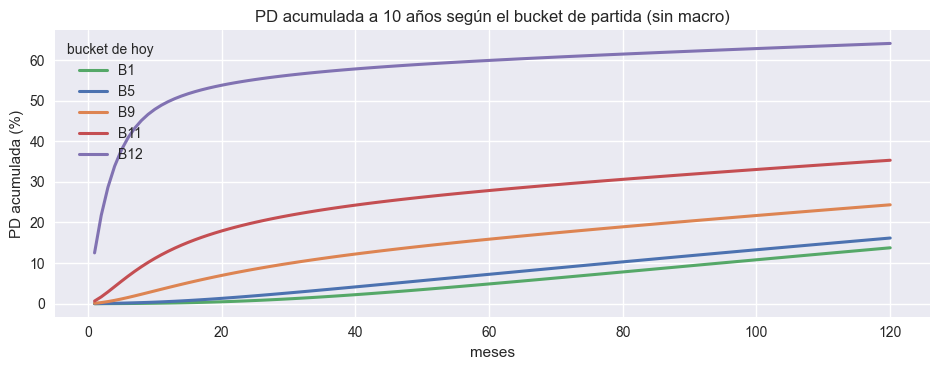

In [25]:
x = es[['id','report_date','est','siguiente','f_sig']].merge(pdm[['id','report_date','b']], on=['id','report_date'], how='left')
x = x.sort_values(['id','report_date'])
x['b_sig'] = x.groupby('id').b.shift(-1)
tr = x[x.b.notna() & x.f_sig.notna()].copy()                         # cuentas vigentes con estado siguiente
tr['dest'] = np.where(tr.siguiente == 'DEFAULT', NB, np.where(tr.siguiente == 'CANCELADO', NB+1, tr.b_sig))
tr = tr[tr.dest.notna()].astype({'b': int, 'dest': int})
tr = tr[tr.f_sig <= pdm.report_date.max()]                         # el mes siguiente tiene que tener PD: si no, solo
                                                                    # se verían los defaults y la estimación se sesga

def conteos(g):
    return np.histogram2d(g.b, g.dest, bins=[np.arange(NB+1), np.arange(NB+3)])[0]
N_mes = {pd.Timestamp(t): conteos(g) for t, g in tr.groupby('report_date')}       # transiciones de cada mes
dev_meses = [t for t in N_mes if t + pd.offsets.MonthEnd(1) <= T0]                # solo las observadas hasta T0
Nd = sum(N_mes[t] for t in dev_meses)
M = Nd / Nd.sum(1, keepdims=True)                                                 # matriz mensual promedio
canc = M[:, NB+1]                                                                 # probabilidad de cancelar
print(f'matriz estimada con {int(Nd.sum()):,} transiciones de {len(dev_meses)} meses')
print('matriz mensual (%), filas = bucket de hoy, columnas = destino el mes siguiente:')
print(pd.DataFrame(M*100, index=NOMBRES, columns=NOMBRES+['DEF','CANC']).round(2).to_string())

def matriz_completa(Mb):
    # agrega las filas absorbentes de DEFAULT y CANCELADO
    P = np.zeros((NB+2, NB+2)); P[:NB] = Mb; P[NB, NB] = P[NB+1, NB+1] = 1
    return P

def recorrer(matrices):
    # multiplica las matrices mes a mes; devuelve hazard (default | vivo) y supervivencia al default,
    # por bucket de partida
    acc = np.eye(NB+2); prev = np.zeros(NB+2); hz = []
    for P in matrices:
        vivo = acc[:NB, :NB].sum(1)                                   # vivo y en cartera al inicio del mes
        acc = acc @ P
        hz.append((acc[:NB, NB] - prev[:NB]) / np.maximum(vivo, 1e-12)); prev = acc[:, NB].copy()
    hz = np.array(hz)                                                 # meses x bucket
    S = np.cumprod(1 - hz, axis=0)                                    # supervivencia al default
    marg = np.vstack([hz[:1], hz[1:] * S[:-1]])                       # PD marginal de default puro
    return hz, S, marg

hz, S, marg = recorrer([matriz_completa(M)] * 120)
ej = 6                                                                # B7, un bucket del medio
print(f'\n{NOMBRES[ej]}: hazard, supervivencia y PD marginal de los primeros meses (sin macro)')
print(pd.DataFrame({'hazard %': hz[:24, ej]*100, 'supervivencia': S[:24, ej], 'marginal %': marg[:24, ej]*100,
                    'acumulada %': marg[:24, ej].cumsum()*100}, index=range(1, 25)).iloc[[0,1,2,5,11,17,23]].round(3).to_string())

fig, ax = plt.subplots(figsize=(9.5, 3.8))
for b_, c_ in zip([0, 4, 8, 10, 11], ['#55a868', '#4c72b0', '#dd8452', '#c44e52', '#8172b2']):
    ax.plot(np.arange(1, 121), marg[:, b_].cumsum()*100, lw=2.2, c=c_, label=NOMBRES[b_])
ax.set_xlabel('meses'); ax.set_ylabel('PD acumulada (%)'); ax.legend(title='bucket de hoy')
ax.set_title('PD acumulada a 10 años según el bucket de partida (sin macro)')
plt.tight_layout(); plt.show()

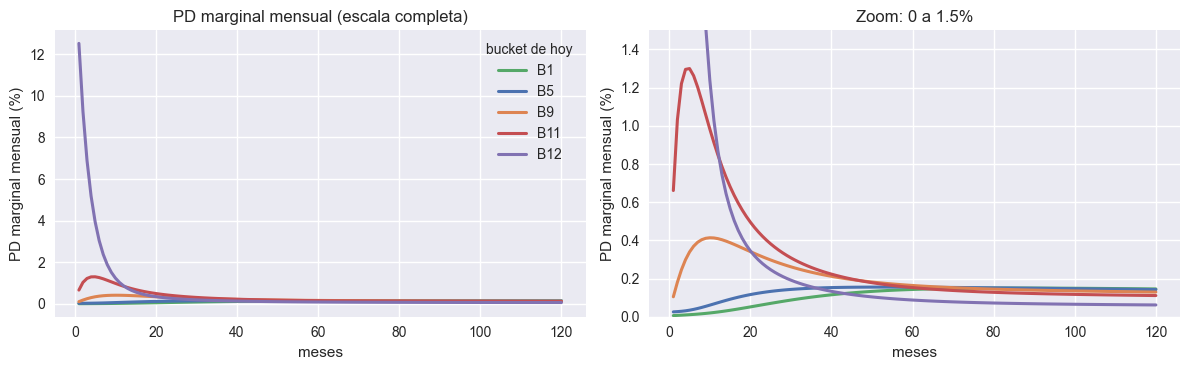

In [26]:
_, _, marg0 = recorrer([matriz_completa(M)] * 120)
cols = zip([0, 4, 8, 10, 11], ['#55a868', '#4c72b0', '#dd8452', '#c44e52', '#8172b2'])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for b_, c_ in cols:
    for ax in axs:
        ax.plot(np.arange(1, 121), marg0[:, b_]*100, lw=2.2, c=c_, label=NOMBRES[b_])
axs[0].set_title('PD marginal mensual (escala completa)')
axs[1].set_ylim(0, 1.5); axs[1].set_title('Zoom: 0 a 1.5%')
for ax in axs:
    ax.set_xlabel('meses'); ax.set_ylabel('PD marginal mensual (%)')
axs[0].legend(title='bucket de hoy')
plt.tight_layout(); plt.show()


## El factor de ciclo Z

La matriz anterior es un **promedio** del desarrollo. En recesión las cuentas empeoran más y en expansión mejoran más. Para capturarlo, toda la matriz se desplaza con **un solo factor de ciclo** (Belkin, Suchower y Forest, de la misma familia que Vasicek):

1. Cada fila se escribe como **umbrales** en la normal: la probabilidad de terminar en un estado igual o peor que *j* es $\Phi(c_j)$.
2. En el mes *t*, todos los umbrales se mueven juntos en $\theta_t$: $\;P(\text{peor o igual que } j) = \Phi\!\left(\frac{c_j + \theta_t}{\sqrt{1-\rho}}\right)$.
3. $\theta_t > 0$ es un mal mes: más cuentas empeoran y más caen. $\theta_t < 0$, uno bueno.

Primero se estima el $\theta_t$ de cada mes con las transiciones observadas; después se explica con la macro. **Esa regresión es la link function de este capítulo**, y es lo que permite proyectar la matriz con escenarios.

La cancelación queda fuera del desplazamiento: se mantiene en su promedio.

ρ del ciclo de migración: 0.0011
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1432      0.007    -19.579      0.000      -0.158      -0.129
u              0.0231      0.001     21.079      0.000       0.021       0.025
g             -0.0176      0.001    -11.819      0.000      -0.020      -0.015
R2 0.849: la macro explica esa parte del movimiento mensual de toda la matriz


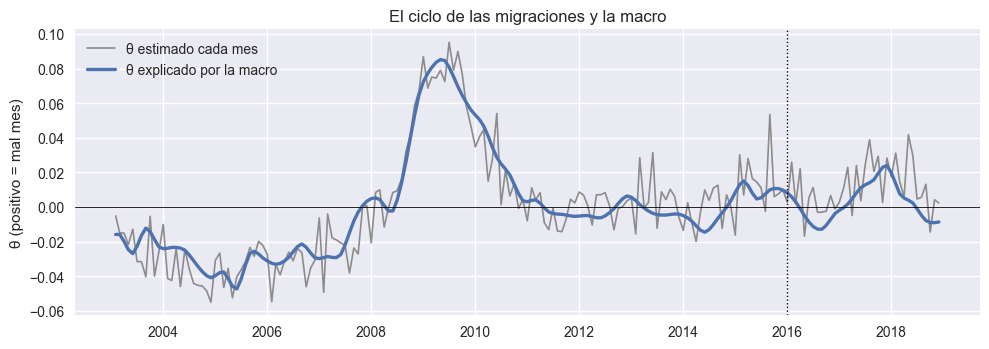

In [8]:
q_nc = M[:, :NB+1] / (1 - canc)[:, None]                              # sin cancelación, de mejor a peor
S_c = np.cumsum(q_nc[:, ::-1], axis=1)[:, ::-1]                       # P(estado igual o peor que j)
UMB = norm.ppf(np.clip(S_c[:, 1:], 1e-12, 1 - 1e-12))                 # umbrales c_j de cada fila

def probs(theta, rho):
    # probabilidades de cada destino (sin cancelación) desplazadas en theta
    Sz = np.hstack([np.ones((NB,1)), norm.cdf((UMB + theta)/np.sqrt(1 - rho)), np.zeros((NB,1))])
    return np.clip(Sz[:, :-1] - Sz[:, 1:], 1e-12, 1)

def matriz_z(theta, rho):
    # matriz completa del mes, desplazada; la cancelación se mantiene en su promedio
    Mb = np.zeros((NB, NB+2)); Mb[:, :NB+1] = probs(theta, rho) * (1 - canc)[:, None]; Mb[:, NB+1] = canc
    return matriz_completa(Mb)

rho = 0.02                                                            # valor inicial; se ajusta a la varianza de theta
for _ in range(3):
    theta = pd.Series({t: minimize_scalar(lambda a: -(N_mes[t][:, :NB+1] * np.log(probs(a, rho))).sum(),
                                          bounds=(-3, 3), method='bounded').x for t in N_mes})
    rho = theta[dev_meses].var()
print(f'ρ del ciclo de migración: {rho:.4f}')

# macro del mes en que ocurre la transición (el mes siguiente al cierre), suavizada en 3 meses
macro_m = pd.DataFrame({'u': mm.uer, 'g': 3 * mm.gdp_growth}).rolling(3, min_periods=1).mean()
D = pd.DataFrame({'theta': theta}).join(macro_m.shift(-1)).dropna()
Dd = D[D.index.isin(dev_meses)]
lk = sm.OLS(Dd.theta, sm.add_constant(Dd[['u','g']])).fit()
print(lk.summary().tables[1])
print(f'R2 {lk.rsquared:.3f}: la macro explica esa parte del movimiento mensual de toda la matriz')
theta_de = lambda u, g: lk.params['const'] + lk.params['u']*np.asarray(u) + lk.params['g']*np.asarray(g)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(D.index, D.theta, c='#8c8c8c', lw=1.2, label='θ estimado cada mes')
ax.plot(D.index, theta_de(D.u, D.g), c='#4c72b0', lw=2.4, label='θ explicado por la macro')
ax.axvline(T0, c='k', ls=':', lw=1); ax.axhline(0, c='k', lw=.6)
ax.set_ylabel('θ (positivo = mal mes)'); ax.legend(); ax.set_title('El ciclo de las migraciones y la macro')
plt.tight_layout(); plt.show()

## Escenarios

Los escenarios salen de un **VAR(1) estimado con la macro observada hasta la fecha de reporte**: 1983 a 2015, 132 trimestres. Nada posterior:

$$x_t - \mu = A\,(x_{t-1} - \mu) + e_t$$

$A$ dice cómo se transmite un shock de una variable a otra de un trimestre al siguiente; $\mu$ es el nivel al que la economía vuelve sola. **Se estiman**, con su error: un banco no conoce la verdadera dinámica de la economía. Cuánto se parecen a la verdad es el tema de la clase 7.

Las trayectorias parten del estado observado en la fecha de reporte:

- **Base**: sin shocks. El VAR revierte solo a su media de largo plazo: es la reversión que pide la norma más allá del horizonte razonable.
- **Adverso**: shocks negativos los primeros cuatro trimestres.
- **Optimista**: shocks positivos más suaves.

Se proyectan en trimestres y se pasan a meses **con la misma función** que la historia. Cada trayectoria se convierte en una trayectoria de $\theta$. Los pesos —50/30/20— son una decisión de gobierno: clase 10.

VAR(1) estimado con 131 trimestres (hasta 2015-12)
nivel de largo plazo estimado: {'gdp_growth': np.float64(0.47), 'uer': np.float64(6.26), 'cpi': np.float64(1.96), 'ir': np.float64(3.59), 'hpi': np.float64(0.82)}
mayor raíz del sistema: 0.897  (menor a 1: los shocks se disipan y la economía revierte)


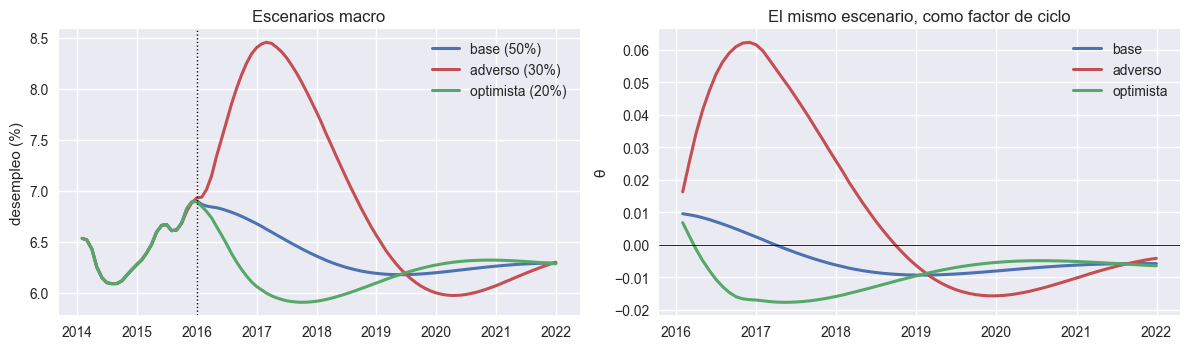

In [9]:
VARS = ['gdp_growth','uer','cpi','ir','hpi']
hist = macro[macro.report_date <= T0][['report_date'] + VARS]           # solo lo observado hasta T0
var = VAR(hist.set_index('report_date')[VARS]).fit(1)                   # VAR(1) por mínimos cuadrados
A = var.coefs[0]                                                        # transmisión entre variables
mu = np.linalg.solve(np.eye(5) - A, var.intercept)                      # nivel de largo plazo implícito
print(f'VAR(1) estimado con {var.nobs} trimestres (hasta {T0:%Y-%m})')
print('nivel de largo plazo estimado:', dict(zip(VARS, mu.round(2))))
print(f'mayor raíz del sistema: {np.abs(np.linalg.eigvals(A)).max():.3f}  (menor a 1: los shocks se disipan y la economía revierte)')
x0 = macro.set_index(macro.report_date.dt.to_period('Q')).loc[T0.to_period('Q'), VARS].values.astype(float)
HQ = HMAX//3 + 8
shocks = {'base': None,
          'adverso':   {0: [-1.2,.18,0,0,-2.0], 1: [-1.0,.16,0,0,-1.8], 2: [-.6,.10,0,0,-1.0], 3: [-.3,.05,0,0,-.5]},
          'optimista': {0: [.5,-.06,0,0,.8], 1: [.4,-.05,0,0,.6], 2: [.2,-.03,0,0,.3]}}
W = {'base': .5, 'adverso': .3, 'optimista': .2}
fq = pd.date_range(T0 + pd.offsets.QuarterEnd(1), periods=HQ, freq='QE')
meses_fut = pd.date_range(T0 + pd.offsets.MonthEnd(1), periods=HMAX, freq='ME')
esc_m, theta_esc = {}, {}
for nom, sh in shocks.items():
    d_, filas = x0 - mu, []
    for t in range(HQ):
        e = np.array(sh[t]) if sh and t in sh else np.zeros(5)
        d_ = A @ d_ + e; filas.append(mu + d_)
    proy = pd.DataFrame(filas, columns=VARS); proy.insert(0, 'report_date', fq)
    m_ = a_mensual(pd.concat([hist, proy], ignore_index=True))
    esc_m[nom] = m_
    s_ = pd.DataFrame({'u': m_.uer, 'g': 3*m_.gdp_growth}).rolling(3, min_periods=1).mean()
    theta_esc[nom] = pd.Series(theta_de(s_.u, s_.g), index=s_.index).reindex(meses_fut).values   # theta de cada mes futuro

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for nom, c_ in zip(esc_m, ['#4c72b0', '#c44e52', '#55a868']):
    s_ = esc_m[nom].uer.loc['2014-01-01':'2021-12-31']
    axs[0].plot(s_.index, s_.values, lw=2.2, c=c_, label=f'{nom} ({W[nom]:.0%})')
    axs[1].plot(meses_fut[:72], theta_esc[nom][:72], lw=2.2, c=c_, label=nom)
axs[0].axvline(T0, c='k', ls=':', lw=1); axs[0].set_ylabel('desempleo (%)'); axs[0].legend(); axs[0].set_title('Escenarios macro')
axs[1].axhline(0, c='k', lw=.6); axs[1].set_ylabel('θ'); axs[1].legend(); axs[1].set_title('El mismo escenario, como factor de ciclo')
plt.tight_layout(); plt.show()

## PD Lifetime de cada cuenta

Para cada escenario se multiplican **360 matrices**, una por mes, cada una desplazada con el $\theta$ de ese mes. Eso da, para cada bucket de partida, el hazard y la PD marginal de cada mes futuro.

Cada cuenta toma la curva de **su bucket en la fecha de reporte**, y se corta en **su vencimiento**: después de vencer ya no puede caer. Las tres curvas se ponderan por escenario.

- **PD a 12 meses**: la suma de las primeras 12 marginales. Es la de Stage 1.
- **PD de vida**: la suma hasta el vencimiento. Es la de Stage 2.

Ojo al leer la PD de vida por bucket: **depende del plazo que le queda a cada cuenta**. Para comparar buckets entre sí se usa un horizonte común, como 5 años.

In [10]:
vivas = c2[c2.report_date == T0][['id','remaining_term']].merge(
        pdm[pdm.report_date == T0][['id','pd_12m','b']], on='id')
b0 = vivas.b.values.astype(int)                                       # bucket de cada cuenta en T0
R = np.minimum(vivas.remaining_term.values.clip(1), HMAX)             # meses hasta su vencimiento
corte = np.arange(HMAX)[None, :] < R[:, None]                         # True mientras no vence

marg_esc = {}
for nom in shocks:
    _, _, mg = recorrer([matriz_z(th_, rho) for th_ in theta_esc[nom]])   # meses x bucket
    marg_esc[nom] = mg[:, b0].T * corte                                    # cuentas x meses, cortado al vencimiento
marg = sum(W[k] * v for k, v in marg_esc.items())                         # ponderado por escenario

print(f'{len(vivas):,} cuentas vigentes al {T0:%Y-%m}')
for k in shocks:
    print(f'  {k:10s}: PD 12 meses {marg_esc[k][:, :12].sum(1).mean()*100:5.2f}% | PD de vida {marg_esc[k].sum(1).mean()*100:5.2f}%')
print(f'  ponderada : PD 12 meses {marg[:, :12].sum(1).mean()*100:5.2f}% | PD de vida {marg.sum(1).mean()*100:5.2f}%')

# la PD de vida se suma hasta el vencimiento de CADA cuenta: depende del plazo que le queda.
# Para comparar buckets se agrega un horizonte común de 5 años.
f_ = lambda fn: [fn(b0 == i) if (b0 == i).any() else np.nan for i in range(NB)]
tb_ = pd.DataFrame({'cuentas': np.bincount(b0, minlength=NB),
                    'plazo remanente (años)': f_(lambda m: R[m].mean()/12),
                    'PD 12 meses': f_(lambda m: marg[m, :12].sum(1).mean()*100),
                    'PD 5 años': f_(lambda m: marg[m, :60].sum(1).mean()*100),
                    'PD de vida': f_(lambda m: marg[m].sum(1).mean()*100)}, index=NOMBRES)
print('\nPD por bucket de partida (ponderada, %):')
print(tb_.round(2).to_string())
print('A 12 meses el orden es estricto y a 5 años se mantiene (B5 y B6 prácticamente empatan). La PD de vida no es monótona'
      ' porque suma hasta el vencimiento: un bucket con plazos más cortos acumula menos meses de riesgo.')

12,264 cuentas vigentes al 2015-12
  base      : PD 12 meses  2.48% | PD de vida 24.99%
  adverso   : PD 12 meses  2.90% | PD de vida 26.69%
  optimista : PD 12 meses  2.34% | PD de vida 24.49%
  ponderada : PD 12 meses  2.58% | PD de vida 25.40%

PD por bucket de partida (ponderada, %):
     cuentas  plazo remanente (años)  PD 12 meses  PD 5 años  PD de vida
B1      1163                    9.31         0.18       4.60       11.89
B2      1124                   11.89         0.25       5.18       16.38
B3      1171                   17.04         0.30       5.76       24.29
B4      1257                   19.03         0.42       6.42       27.58
B5      1216                   19.14         0.58       6.89       28.05
B6      1207                   13.21         0.78       6.85       20.30
B7      1285                   14.50         1.25       8.86       23.61
B8      1283                   15.81         2.07      11.37       27.47
B9      1266                   16.80         4.20     

## Backtest: cómo se diseña

**La frontera es la fecha de reporte.** Los cortes de los buckets, la matriz, el factor Z y su relación con la macro se estimaron **solo con lo observado hasta diciembre 2015**. Lo que sigue compara contra lo que pasó **después**: enero 2016 a diciembre 2019. Ese es el fuera de tiempo.

**Se valida el nivel**, de dos formas:

1. **Por cohorte.** Las cuentas vigentes en diciembre 2015 se siguen 48 meses. Se compara la proporción que cayó en default contra lo proyectado, a 12, 24, 36 y 48 meses, en total y por bucket. Se usa la **incidencia**: la proporción de la cohorte original que entró a default, con la cancelación como salida competidora, igual en lo observado y en lo proyectado.
2. **En el tiempo.** En cada cierre, la PD a 12 meses de la matriz contra la DR que ocurrió en su ventana, con banda Vasicek. Antes de 2016 es ajuste; desde 2016, fuera de tiempo puro.

**Se separan dos errores** corriendo la proyección dos veces: con los **escenarios** —lo que se sabía en 2015— y con la **macro que realmente ocurrió**:

- **Error de escenario** = con la macro real − con escenarios. La economía fue distinta de la proyectada.
- **Error de modelo** = observado − con la macro real. Aun conociendo la macro, el modelo se desvía.

In [11]:
H = 48
mac_real = macro_m.reindex(meses_fut[:H]).ffill()
theta_real = theta_de(mac_real.u, mac_real.g)                         # theta con la macro que ocurrió

def incidencia(thetas):
    # proporción de cada bucket de partida que entró a default a cada mes (cancelación como salida)
    acc = np.eye(NB+2); out = []
    for th_ in thetas: acc = acc @ matriz_z(th_, rho); out.append(acc[:NB, NB].copy())
    return np.array(out)                                              # meses x bucket

inc_real = incidencia(theta_real)
inc_esc = sum(W[k] * incidencia(theta_esc[k][:H]) for k in shocks)

post = es[(es.report_date > T0) & es.id.isin(vivas.id)]
mes_def = vivas.id.map(post[post.est == 'DEFAULT'].groupby('id').p.min() - pos[T0])     # mes de entrada a default
mes_can = vivas.id.map(post[post.est == 'CANCELADO'].groupby('id').p.min() - pos[T0])   # mes de cancelación

filas = []
for k in [12, 24, 36, 48]:
    o = (mes_def <= k).mean()*100; e_ = inc_esc[k-1, b0].mean()*100; r_ = inc_real[k-1, b0].mean()*100
    filas.append({'horizonte': f'{k} meses', 'con escenarios': e_, 'con la macro real': r_, 'observado': o,
                  'error de escenario': r_ - e_, 'error de modelo': o - r_})
print('1. COHORTE dic-2015 — proporción que entró a default (%):')
print(pd.DataFrame(filas).set_index('horizonte').round(2).to_string())

print('\npor bucket de partida, a 48 meses (%):')
pb = pd.DataFrame({'cuentas': np.bincount(b0, minlength=NB),
                   'observado': [(mes_def[b0 == i] <= H).mean()*100 if (b0 == i).any() else np.nan for i in range(NB)],
                   'matriz, macro real': [inc_real[H-1, i]*100 for i in range(NB)]}, index=NOMBRES)
print(pb.round(2).to_string())

1. COHORTE dic-2015 — proporción que entró a default (%):
           con escenarios  con la macro real  observado  error de escenario  error de modelo
horizonte                                                                                   
12 meses             2.58               2.38       2.19               -0.20            -0.19
24 meses             4.77               4.41       4.52               -0.36             0.11
36 meses             6.58               6.24       6.49               -0.34             0.25
48 meses             8.11               7.79       8.14               -0.32             0.35

por bucket de partida, a 48 meses (%):
     cuentas  observado  matriz, macro real
B1      1163       2.49                2.89
B2      1124       3.11                3.27
B3      1171       3.59                3.61
B4      1257       5.25                4.14
B5      1216       5.51                4.70
B6      1207       7.13                5.40
B7      1285       8.25             

### El orden de hoy no vale para siempre

Esta tabla muestra por qué hace falta la matriz. Se toman las cuentas vigentes en diciembre 2015, se ordenan por su PD de ese día en diez grupos, y se mide qué proporción cayó entre el **mes 13 y el 48**, entre las que sobrevivieron el primer año.

Se compara con dos proyecciones:

- **PD congelada**: la PD de hoy aplicada igual todos los años. Es el supuesto del desplazamiento del libro, el camino B.
- **Matriz**: deja que cada cuenta cambie de bucket con el tiempo.

Si el orden de hoy valiera para siempre, la distancia entre el grupo más riesgoso y el más sano se mantendría. La realidad dice otra cosa.

In [12]:
acc = np.eye(NB+2); A_ = []
for th_ in theta_real: acc = acc @ matriz_z(th_, rho); A_.append(acc[:NB].copy())
A_ = np.array(A_)                                                     # meses x bucket x estado
vivo12 = A_[11, b0, :NB].sum(1)
p_matriz = (A_[H-1, b0, NB] - A_[11, b0, NB]) / vivo12               # caer en 13-48 | vivo al mes 12
h0 = 1 - (1 - vivas.pd_12m.values)**(1/12)                            # PD de hoy, en hazard mensual
p_congelada = 1 - (1 - h0)**36                                        # la misma PD los 36 meses siguientes
sobrevive12 = ~(mes_def <= 12) & ~(mes_can <= 12)
t13 = pd.DataFrame({'decil': pd.qcut(vivas.pd_12m, 10, labels=False) + 1,
                    'observado': ((mes_def > 12) & (mes_def <= H)).astype(float),
                    'PD congelada': p_congelada, 'matriz': p_matriz})[sobrevive12]
t13 = t13.groupby('decil').mean()*100
print('caída entre los meses 13 y 48 (%), por decil de la PD de diciembre 2015:')
print(t13.round(2).T.to_string())
for c_ in ['observado', 'PD congelada', 'matriz']:
    print(f'  distancia decil 10 / decil 1, {c_:13s}: {t13.loc[10, c_]/t13.loc[1, c_]:5.1f} veces')

caída entre los meses 13 y 48 (%), por decil de la PD de diciembre 2015:
decil           1     2     3     4     5     6     7     8      9      10
observado     2.33  3.29  3.74  5.24  5.30  5.48  7.33  9.31   9.89  15.03
PD congelada  0.95  1.29  1.58  1.89  2.36  3.38  4.84  7.08  11.83  27.02
matriz        2.85  3.24  3.63  4.11  4.59  5.23  6.28  7.63   9.72  13.14
  distancia decil 10 / decil 1, observado    :   6.5 veces
  distancia decil 10 / decil 1, PD congelada :  28.4 veces
  distancia decil 10 / decil 1, matriz       :   4.6 veces


### En el tiempo: la PD a 12 meses de cada cierre

En cada cierre, las cuentas vigentes se reparten en buckets y la matriz proyecta los 12 meses de su ventana con el $\theta$ de la macro que ocurrió. Se compara contra la DR observada.

La banda es la de **Vasicek**: ruido de muestreo más la correlación de default que la macro **no** explica, estimada con los cierres de diciembre del desarrollo.

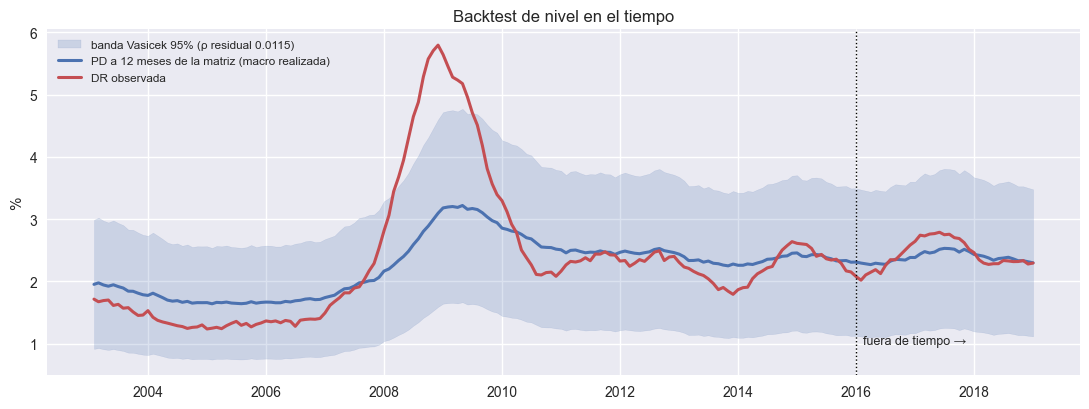

período                         sesgo  error medio  fuera de la banda
desarrollo 2003-2014           -0.10pp       0.49pp        17 de 144
fuera de tiempo 2016-2018      -0.05pp       0.13pp         0 de 36
crisis 2008-2009               -1.68pp       1.68pp        17 de 24
pico de la DR 2008-11 (5.80%) | pico de la matriz 2009-04 (3.22%)


In [13]:
xb = c2[['id','report_date','default_event']].merge(pdm[['id','report_date','b']], on=['id','report_date'])
theta_hist = pd.Series(theta_de(macro_m.u, macro_m.g), index=macro_m.index)
filas = []
for t, g in xb.groupby('report_date'):
    dist = np.bincount(g.b.astype(int), minlength=NB) / len(g)       # cómo se reparte la cartera en buckets
    ths = theta_hist.reindex(pd.date_range(t + pd.offsets.MonthEnd(1), periods=13, freq='ME')).ffill().values
    acc = np.eye(NB+2)
    for s_, th_ in enumerate(ths):
        acc = acc @ matriz_z(th_, rho)
        if s_ == 0: primer = acc[:NB, NB].copy()                      # el primer mes no es de la ventana
    filas.append({'fecha': t, 'dr': g.default_event.mean(), 'pd': dist @ (acc[:NB, NB] - primer), 'n': len(g)})
bt = pd.DataFrame(filas).set_index('fecha')

an = bt[(bt.index.month == 12) & (bt.index <= T0 - pd.DateOffset(months=12))]
xr = norm.ppf(an.dr) - norm.ppf(an.pd); rho_res = xr.var(ddof=1) / (1 + xr.var(ddof=1))
qv = lambda p, a: norm.cdf((norm.ppf(p) + np.sqrt(rho_res)*norm.ppf(a)) / np.sqrt(1 - rho_res))
sd = np.sqrt(((qv(bt.pd, .975) - qv(bt.pd, .025))/3.92)**2 + bt.pd*(1 - bt.pd)/bt.n)
bt['lo'], bt['hi'] = bt.pd - 1.96*sd, bt.pd + 1.96*sd
bt['fuera'] = (bt.dr < bt.lo) | (bt.dr > bt.hi)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(bt.index, bt.lo*100, bt.hi*100, color='#4c72b0', alpha=.2, label=f'banda Vasicek 95% (ρ residual {rho_res:.4f})')
ax.plot(bt.index, bt.pd*100, c='#4c72b0', lw=2.2, label='PD a 12 meses de la matriz (macro realizada)')
ax.plot(bt.index, bt.dr*100, c='#c44e52', lw=2.2, label='DR observada')
ax.axvline(T0, c='k', ls=':', lw=1); ax.text(T0, 1.0, '  fuera de tiempo →', fontsize=9)
ax.set_ylabel('%'); ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('Backtest de nivel en el tiempo')
plt.tight_layout(); plt.show()

print(f'{"período":28s} {"sesgo":>8s} {"error medio":>12s} {"fuera de la banda":>18s}')
for nom, b_ in [('desarrollo 2003-2014', bt[bt.index <= '2014-12-31']), ('fuera de tiempo 2016-2018', bt[bt.index > T0]),
                ('crisis 2008-2009', bt['2008':'2009'])]:
    e = b_.pd - b_.dr
    print(f'{nom:28s} {e.mean()*100:+7.2f}pp {e.abs().mean()*100:10.2f}pp {b_.fuera.sum():>9d} de {len(b_)}')
print(f'pico de la DR {bt.dr.idxmax():%Y-%m} ({bt.dr.max()*100:.2f}%) | pico de la matriz {bt.pd.idxmax():%Y-%m} ({bt.pd.max()*100:.2f}%)')

## Cómo leer el backtest

**Lo que funciona.** El nivel acierta por cohorte en los cuatro horizontes y por bucket; en el tiempo sigue a la DR, y fuera de tiempo cae dentro de la banda. Y la matriz reproduce la reversión a la media que la PD congelada ignora.

**Lo que no es perfecto.** En la crisis de 2008-2009 el pico llega en el momento justo pero **más bajo** que la DR. Un modelo estimado sobre el ciclo completo comprime los extremos: un solo factor mueve toda la matriz, y en la crisis el default se concentró en la cola más de lo que las migraciones explican. La respuesta de un banco no es forzar el modelo para que calce un episodio, sino un **ajuste experto en estrés**: tema de la clase 10.

**Lo que sigue.**
- **LGD** — capítulo 4. La cura y el castigo de este capítulo definen cuánto se pierde una vez en default.
- **EAD** — capítulo 5, con el prepago.
- **ECL** — capítulo 6: marginal × LGD × EAD × descuento, ponderado por escenario. Stage 1 suma los primeros 12 meses; Stage 2, hasta el vencimiento.